In [4]:
edats ={}
edats["ana"] = 30
edats ["bob"] = 25
print(edats["ana"])
print("carla" in edats)

30
False


In [5]:
edats= [("ana","bob"), ("ana","bob"), ("bob","ana")]
comptador ={}
for parelles in edats:
    if parelles in comptador:
        comptador[parelles]=comptador[parelles] +1
    else:
        comptador[parelles]= 1 
print(comptador)

{('ana', 'bob'): 2, ('bob', 'ana'): 1}


In [6]:
edats= [("ana","bob"), ("ana","bob"), ("bob","ana")]
comptador ={}
for parelles in edats:
    comptador[parelles]=comptador.get(parelles,0)+1
print(comptador)

{('ana', 'bob'): 2, ('bob', 'ana'): 1}


In [7]:
import re

def extract_mentions(text):
    return re.findall("@([a-zA-Z0-9_]{5,20})", text)

tweets = [
    ("ana_01", "hola @bob_02 i @carla_3"),
    ("ana_01", "RT @bob_02: bon dia"),
    ("bob_02", "gràcies @ana_01"),
]


In [8]:
mentions_counter={}
for actor, text in tweets:
    mencions=extract_mentions(text)
    for mencio in mencions:
        clau=(actor, mencio)
        mentions_counter[clau]=mentions_counter.get(clau,0)+1
print(mentions_counter)

{('ana_01', 'bob_02'): 2, ('ana_01', 'carla_3'): 1, ('bob_02', 'ana_01'): 1}


In [9]:
import json

linia = '{"user": {"screen_name": "ana_01"}, "full_text": "hola @bob_02"}'
tweet = json.loads(linia)

print(type(tweet))
print(tweet["full_text"])
print(tweet["user"]["screen_name"])

<class 'dict'>
hola @bob_02
ana_01


In [10]:
with open("proves.txt", "r", encoding="utf-8") as fitxer:
    for linia in fitxer:
        print(linia)

{"user": {"screen_name": "ana_01"}, "full_text": "hola @bob_02 i @carla_3"}

{"user": {"screen_name": "bob_02"}, "full_text": "gràcies @ana_01"}


In [11]:
import gzip
mentions_counter={}
with gzip.open("data/CovidLockdownCatalonia.json.gz", "rt",encoding="utf-8") as fitxer:
    for linia in fitxer:
        tweet=json.loads(linia)
        autor = tweet["user"]["screen_name"]
        text = tweet["full_text"] 
        mencions=extract_mentions(text)
        for mencio in mencions:
            clau=(autor, mencio)
            mentions_counter[clau]=mentions_counter.get(clau, 0)+1
    for (u, v), pes in mentions_counter.items():
        if (v,u) in mentions_counter and u<v:
            total = pes + mentions_counter.get((v,u),0)
            if total > 8:
                print(f"Accounts @{u} and @{v} mention each other {total} times")



In [12]:
import io
import csv

OUTPUT_ALL_EDGES_FILENAME = "CovidLockdownCatalonia.csv"
OUTPUT_FILTERED_EDGES_FILENAME = "CovidLockdownCatalonia-min-weight-filtered.csv"
OUTPUT_CO_MENTIONS_FILENAME = "CovidLockdownCatalonia-co-mentions.csv"

In [128]:
lines_written=0
with io.open(OUTPUT_FILTERED_EDGES_FILENAME, "w") as output_file:
    writer = csv.writer(output_file, delimiter='\t', quotechar='"')
    writer.writerow(["Source", "Target", "Weight"])
    for key in mentions_counter:
            author = key[0]
            mention = key[1]
            weight = mentions_counter[key]
            if weight > 3:
                writer.writerow([author, mention, weight])
                lines_written+=1
print(f"Wrote {lines_written} lines to file {OUTPUT_FILTERED_EDGES_FILENAME}")

Wrote 81 lines to file CovidLockdownCatalonia-min-weight-filtered.csv


In [14]:
with open(OUTPUT_FILTERED_EDGES_FILENAME, "r") as f:
    lector = csv.DictReader(f, delimiter="\t")
    for fila in lector:
        print(fila)      # mira què és exactament
        break


{'Source': 'AlfonsGorina', 'Target': 'movieweb', 'Weight': '5'}


In [15]:
import networkx as nx
g = nx.DiGraph()
g.add_edge("ana", "bob", weight=5)
print(g.edges(data=True))

[('ana', 'bob', {'weight': 5})]


In [16]:
g = nx.DiGraph()

with open(OUTPUT_FILTERED_EDGES_FILENAME, "r") as f:
    lector = csv.DictReader(f, delimiter="\t")
    for fila in lector:
        g.add_edge(fila['Source'], fila['Target'], weight=int(fila['Weight']))
list(nx.get_edge_attributes(g, 'weight').items())[:10]
g.number_of_edges()

81

In [17]:
components = list(nx.weakly_connected_components(g))
print(len(components))
print(type(components[0]))
print(components[0])

49
<class 'set'>
{'AlfonsGorina', 'movieweb'}


In [18]:
lcc = g.subgraph(max(components, key=len)).copy()
print(lcc.number_of_nodes()) 

15


In [19]:
# Betweenness calculada sobre el graf no dirigit (només per a visualització)
no_dirigit = lcc.to_undirected()
bet = nx.edge_betweenness_centrality(no_dirigit, weight='weight')

# Guardem el valor a cada aresta del graf dirigit
for u, v in lcc.edges():
    if (u, v) in bet:
        lcc[u][v]['betweenness'] = bet[(u, v)]
    else:
        lcc[u][v]['betweenness'] = bet[(v, u)]   # NetworkX l'ha guardada en l'ordre contrari

In [20]:
mides=[lcc.in_degree(node) for node in lcc.nodes()]
print(mides)

[3, 0, 0, 0, 0, 1, 4, 0, 0, 0, 0, 0, 3, 2, 1]


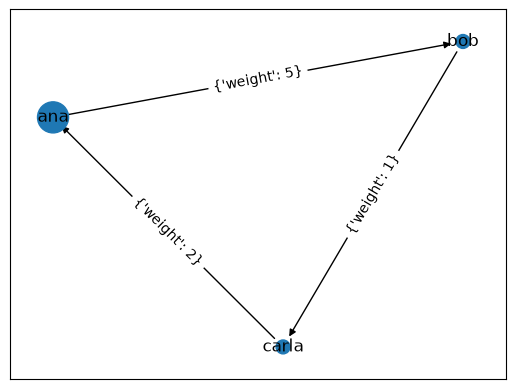

In [21]:
import networkx as nx
import matplotlib.pyplot as plt

g_prova = nx.DiGraph()
g_prova.add_edge("ana", "bob", weight=5)
g_prova.add_edge("bob", "carla", weight=1)
g_prova.add_edge("carla", "ana", weight=2)


pos_prova=nx.spring_layout(g_prova, seed=42)
nx.draw_networkx_nodes(g_prova,pos_prova,node_size=(500,100,100))
nx.draw_networkx_edges(g_prova,pos_prova)
nx.draw_networkx_labels(g_prova,pos_prova)
nx.draw_networkx_edge_labels(g_prova,pos_prova)

plt.show()

[300, 0, 0, 0, 0, 100, 400, 0, 0, 0, 0, 0, 300, 200, 100] [5, 5, 5, 5, 6, 4, 4, 5, 9, 4, 4, 4, 4, 4]


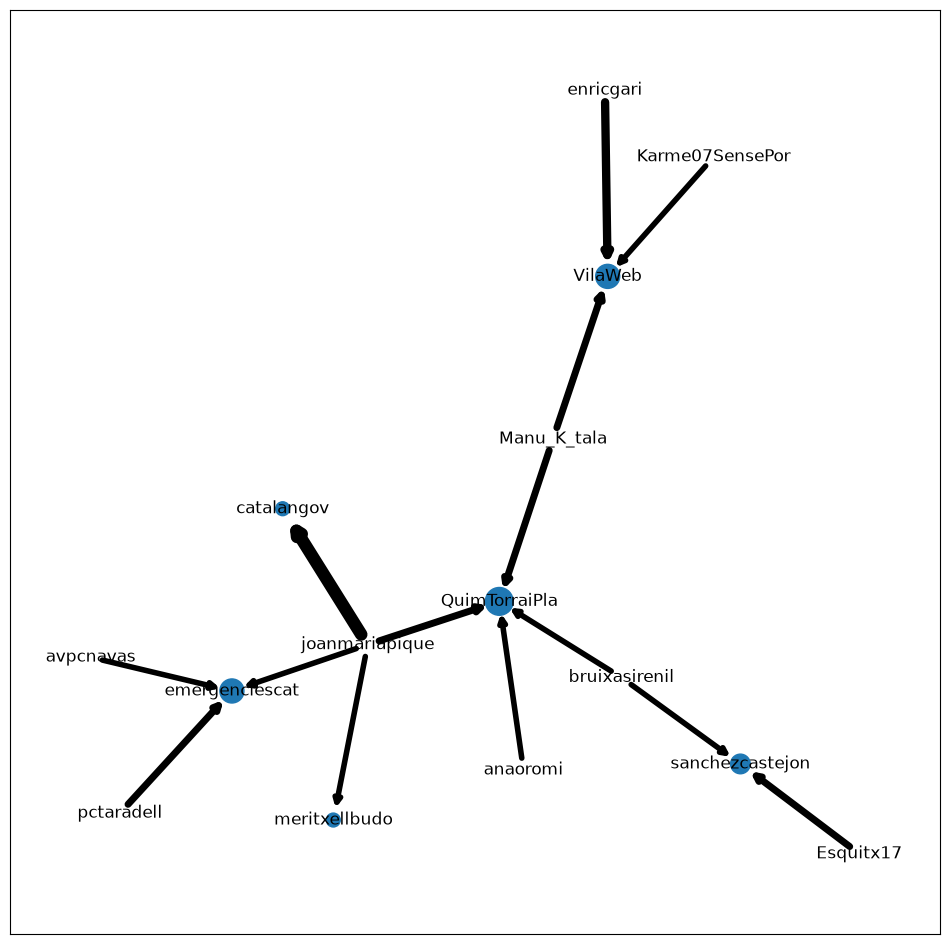

[5, 5, 5, 5, 6, 4, 4, 5, 9, 4, 4, 4, 4, 4]
14 14


In [22]:
mides= [lcc.in_degree(node)*100 for node in lcc.nodes()]
gruixos=[lcc[u][v]['weight'] for u, v in lcc.edges()]
print(mides,gruixos)
plt.figure(figsize=(12,12))
pos_lcc=nx.spring_layout(lcc,weight='betweenness',method='energy',k=0.1,seed=42)
nx.draw_networkx_edges(lcc, pos_lcc, width=gruixos, arrows=True)
nx.draw_networkx_nodes(lcc,pos_lcc,node_size=(mides))
nx.draw_networkx_labels(lcc,pos_lcc)
plt.savefig("mentions-largest-cc.png",dpi=200)
plt.show()
print(gruixos)
print(len(gruixos), lcc.number_of_edges())

In [23]:
g_undirected= lcc.to_undirected()
d=nx.diameter(g_undirected,e=None,usebounds=False,weight=None)
mida= 100*nx.number_of_nodes(g_undirected)/nx.number_of_nodes(g)
print(mida)
componentmaxim=sorted(components,key=len,reverse=True)
print(len(componentmaxim[1]))
print(d)

11.71875
10
6


In [24]:
import networkx as nx
import matplotlib.pyplot as plt

karate_club = nx.read_gml('data/karate-club/karate.gml', label=None)
print(karate_club.number_of_nodes(), karate_club.number_of_edges())

34 78


In [27]:
kc_node_betweenness = nx.betweenness_centrality(karate_club)
kc_edge_betweenness = nx.edge_betweenness_centrality(karate_club)

In [53]:
with open("data/karate-club/karate-factions.csv", "r") as fitxer:
    next(fitxer)
    for linia in fitxer:
        person, faccio= linia.strip().split(" ")
        karate_club.nodes[int(person)]['faction']= faccio
print(karate_club.nodes(data='faction'))

[(1, 'A'), (2, 'A'), (3, 'A'), (4, 'A'), (5, 'A'), (6, 'A'), (7, 'A'), (8, 'A'), (9, 'A'), (10, 'B'), (11, 'A'), (12, 'A'), (13, 'A'), (14, 'A'), (15, 'B'), (16, 'B'), (17, 'A'), (18, 'A'), (19, 'B'), (20, 'A'), (21, 'B'), (22, 'A'), (23, 'B'), (24, 'B'), (25, 'B'), (26, 'B'), (27, 'B'), (28, 'B'), (29, 'B'), (30, 'B'), (31, 'B'), (32, 'B'), (33, 'B'), (34, 'B')]


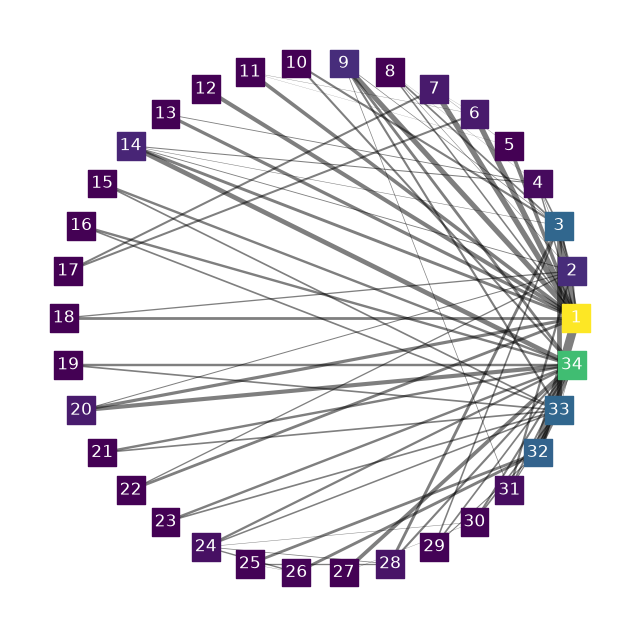

In [ ]:
pos_karate=nx.circular_layout(karate_club)
plt.figure(figsize=(8,8))
colors_nodes=[kc_node_betweenness[node] for node in karate_club.nodes()]
gruixos_arestes=[kc_edge_betweenness[(u,v)]*50 for (u,v) in karate_club.edges()]
nx.draw_networkx_nodes(karate_club,pos_karate,node_shape='s',node_color=colors_nodes,node_size=400,cmap=plt.cm.viridis)
nx.draw_networkx_edges(karate_club,pos_karate,alpha=0.5,width=gruixos_arestes)
nx.draw_networkx_labels(karate_club,pos_karate,font_color='white')
plt.axis('off')
plt.show()

17 17


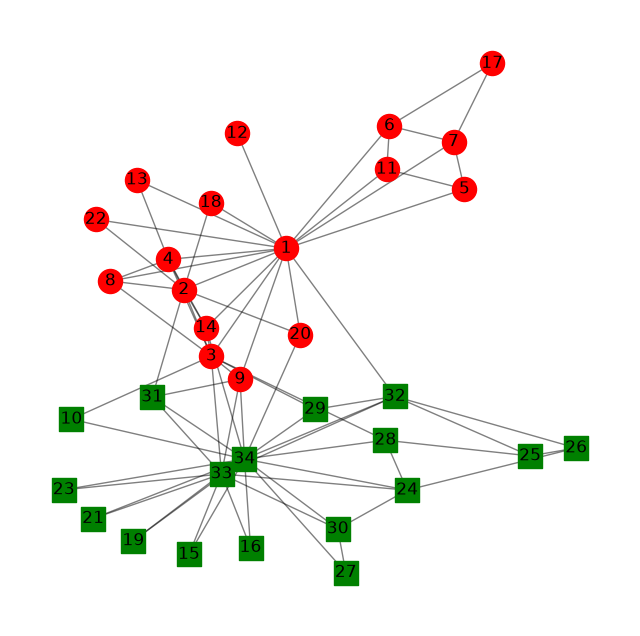

In [56]:
grup_1 = [n for n, f in karate_club.nodes(data='faction') if f == 'A']
grup_2 = [n for n, f in karate_club.nodes(data='faction') if f== 'B']
print(len(grup_1),len(grup_2))
pos=nx.spring_layout(karate_club,seed=42)
plt.figure(figsize=(8, 8))
nx.draw_networkx_nodes(karate_club, pos, nodelist=grup_1, node_shape='o', node_color='red')
nx.draw_networkx_nodes(karate_club, pos, nodelist=grup_2, node_shape='s', node_color='green')
nx.draw_networkx_edges(karate_club,pos,alpha=0.5)
nx.draw_networkx_labels(karate_club,pos)
plt.axis('off')
plt.show()

{16: 1, 9: 1, 10: 1, 6: 2, 3: 6, 4: 6, 5: 3, 2: 11, 1: 1, 12: 1, 17: 1}


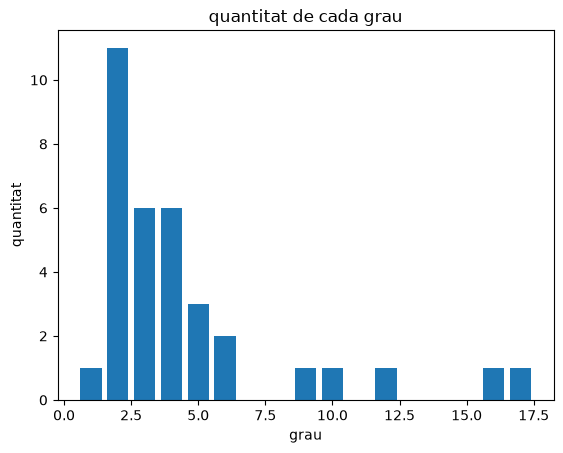

In [70]:
comptador_graus={}
for node, grau in karate_club.degree():
    comptador_graus[grau]=comptador_graus.get(grau,0)+1
print(comptador_graus)
plt.bar(list(comptador_graus.keys()), list(comptador_graus.values()))
plt.xlabel("grau")
plt.ylabel("quantitat")
plt.title("quantitat de cada grau")
plt.show()

In [71]:
INPUT_INGR_FILENAME = "data/flavors-network/ingredients.tsv"
INPUT_COMP_FILENAME = "data/flavors-network/compounds.tsv"
INPUT_INGR_COMP_FILENAME = "data/flavors-network/ingredient-compound.tsv"
import pandas as pd

ingredients = pd.read_csv(INPUT_INGR_FILENAME, sep="\t")
display(ingredients.head(3))

compounds = pd.read_csv(INPUT_COMP_FILENAME, sep="\t")
display(compounds.head(3))

ingr_comp = pd.read_csv(INPUT_INGR_COMP_FILENAME, sep="\t")
display(ingr_comp.head(3))

,ingredient_id,ingredient_name,ingredient_category
0,0,magnolia_tripetala,flower
1,1,calyptranthes_parriculata,plant
2,2,chamaecyparis_pisifera_oil,plant derivative


,compound_id,compound_name,compound_code
0,0,jasmone,488-10-8
1,1,5-methylhexanoic_acid,628-46-6
2,2,l-glutamine,56-85-9


,ingredient_id,compound_id
0,1392,906
1,1259,861
2,1079,673


In [72]:
print(ingredients.columns)
print(compounds.columns)
print(ingr_comp.columns)



Index(['ingredient_id', 'ingredient_name', 'ingredient_category'], dtype='str')
Index(['compound_id', 'compound_name', 'compound_code'], dtype='str')
Index(['ingredient_id', 'compound_id'], dtype='str')


In [94]:
pas1 = ingredients.set_index('ingredient_id').join(ingr_comp.set_index('compound_id'), how='inner')
print(pas1.head())

                  ingredient_name ingredient_category  ingredient_id
ingredient_id                                                       
0              magnolia_tripetala              flower           1120
0              magnolia_tripetala              flower            506
0              magnolia_tripetala              flower           1348
0              magnolia_tripetala              flower           1495
0              magnolia_tripetala              flower            778


In [95]:
flavors = pas1.set_index('ingredient_id').join(compounds.set_index('compound_id'), how='inner')
display(flavors.head(10))
print(flavors.shape)

,ingredient_name,ingredient_category,compound_name,compound_code
ingredient_id,,,,
506,magnolia_tripetala,flower,benzyl_tiglate,5837-78-5
778,magnolia_tripetala,flower,methyl_heptanoate,106-73-0
908,magnolia_tripetala,flower,3-phenylpropyl_acetate,122-72-5
949,magnolia_tripetala,flower,benzyl_isovalerate,103-38-8
143,magnolia_tripetala,flower,"4-[(2,6,6)-trimethyl-cyclohex-1-enyl]-but-2-en...",35044-68-9
439,magnolia_tripetala,flower,hexyl_hexanoate,6378-65-0
680,magnolia_tripetala,flower,neryl_acetate,141-12-8
123,magnolia_tripetala,flower,dehydrodihydroionone,20483-36-7
497,magnolia_tripetala,flower,3-(methylthio)_hexyl_acetate,51755-85-2


(26440, 4)


In [105]:
flavors = flavors.drop(columns=['ingredient_category','compound_code'])
flavors = flavors.sort_values(['ingredient_name', 'compound_name'])
flavors = flavors.reset_index(drop=True)
display(flavors.head(10))
flavors.to_csv("flavors.tsv", sep="\t", index=False)

,ingredient_name,compound_name
0,abies_balsamea_oil,(+/?)-2-(5-methyl-5-vinyltetrahydrofuran-2-yl)...
1,abies_balsamea_oil,1-ethoxy-3-methyl-2-butene
2,abies_balsamea_oil,"2,6,6-trimethyl-6-vinyltetrahydropyran"
3,abies_balsamea_oil,2-heptenal
4,abies_balsamea_oil,2-methoxy-3_(5_and_6)-isopropylpyrazine
5,abies_balsamea_oil,2-oxobutyric_acid
6,abies_balsamea_oil,"3,5-diethyl-2-methylpyrazine"
7,abies_balsamea_oil,3-phenylpropyl_acetate
8,abies_balsamea_oil,acetanisole
9,abies_balsamea_oil,benzyl_butyrate


In [106]:
display(pd.read_csv("flavors.tsv",sep="\t").head())


,ingredient_name,compound_name
0,abies_balsamea_oil,(+/?)-2-(5-methyl-5-vinyltetrahydrofuran-2-yl)...
1,abies_balsamea_oil,1-ethoxy-3-methyl-2-butene
2,abies_balsamea_oil,"2,6,6-trimethyl-6-vinyltetrahydropyran"
3,abies_balsamea_oil,2-heptenal
4,abies_balsamea_oil,2-methoxy-3_(5_and_6)-isopropylpyrazine


In [112]:
flavors_graph=nx.Graph()
with open("flavors.tsv","r") as fitxer:
    next(fitxer)
    for linia in fitxer:
        ingredient, compost=linia.strip().split("\t")
        flavors_graph.add_edge(ingredient,compost)

print(f"Number of nodes: {flavors_graph.number_of_nodes()}")
print(f"Number of edges: {flavors_graph.number_of_edges()}")
print(f"Number of connected components: {nx.number_connected_components(flavors_graph)}")


Number of nodes: 2173
Number of edges: 26440
Number of connected components: 20


In [127]:
categories = dict(zip(ingredients['ingredient_name'], ingredients['ingredient_category']))
nx.set_node_attributes(flavors_graph, values=categories, name='category')

for node in ['caffeine']:
    print(f"{node:<10}: {flavors_graph.nodes[node]}")


caffeine  : {}
